# Flattened (non-nested) CV: combined individual dataset

Each model is tuned with k-fold CV on a training split and then scored once on a held-out test split.

## Setup

In [11]:
%cd "/home/adam/personal/msc/thesis/Data and code"
import contextlib, io, os, pickle, warnings
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import f1_score, recall_score, confusion_matrix

from adamthesis.data_loading import DatasetLoader, slim_down_features
from adamthesis.gridsearch import (GridSearchExperiment, get_all_models_to_run_majority_baseline,
                                   _revision_experiments, _revision_segments)

warnings.filterwarnings('ignore')

K_VALUES  = [5]
TEST_SIZE = 0.3          # swap to 0.2 for an 80/20 split
SEED      = 42
RERUN     = False        # True = ignore cached pickles and refit everything
PICKLE_DIR = f'logs/pickles/flattened/test{int(TEST_SIZE*100)}'
os.makedirs(PICKLE_DIR, exist_ok=True)

SEGMENTS   = [s for s, _ in _revision_segments()]          # individual-491, individual-492
SEG_TARGET = dict(_revision_segments())
SEG_LABELS = {'individual-491': 'Individual 491', 'individual-492': 'Individual 492'}
FEATURE_FNS = dict(_revision_experiments())                # twq, academic, both, old-prereqs, new-prereqs
FEAT_LABELS = {'twq': 'TWQ', 'academic': 'Academic', 'both': 'Combined',
               'old-prereqs': 'Old prereqs', 'new-prereqs': 'New prereqs'}
BASELINE = 'baseline_classifier'
MODELS   = ['random_forest', 'svc', 'logistic_regression', 'naive_bayes', 'KNN', 'DecisionTree']
NI_MARGIN = 0.10

/home/adam/personal/msc/thesis/Data and code


## Helpers

In [12]:
def team_labels(y, groups):
    # One label per team: 1 if at least half of the team's students are AA, else 0.
    teams = np.unique(groups)
    share = np.array([y[groups == t].mean() for t in teams])
    return teams, share, (share >= 0.5).astype(int)


def team_disjoint_holdout(y, groups, test_size=TEST_SIZE, seed=SEED):
    # Stratified train/test split over TEAMS. Returns positional (train_idx, test_idx) over students.
    #
    # Step 1: collapse students to teams; each team gets a label (team_labels).
    # Step 2: train_test_split on the list of team IDs with stratify=team label, so about test_size of
    # the AA teams and about test_size of the non-AA teams go to the test set (one fixed seed).
    # Step 3: expand back to students; every student of a test team is a test student.
    # Models are still trained and scored on individual students; only the assignment unit is the team.
    teams, _, label = team_labels(y, groups)
    _, test_teams = train_test_split(teams, test_size=test_size, stratify=label, random_state=seed)
    is_test = np.isin(groups, test_teams)
    train_idx, test_idx = np.where(~is_test)[0], np.where(is_test)[0]
    assert not set(groups[train_idx]) & set(groups[test_idx]), 'team leakage between train and test'
    return train_idx, test_idx


def _base_loader(seg):
    return DatasetLoader().use_combined_individual_data_csv().set_target(SEG_TARGET[seg])


# One split per segment, shared by every feature set and every k.
SPLITS = {}
for seg in SEGMENTS:
    loader = _base_loader(seg)
    groups = loader.get_groups()
    _, y = loader.use_teamwork_features().get_features_and_target()
    tr, te = team_disjoint_holdout(y.to_numpy(), groups)
    SPLITS[seg] = (tr, te, groups)
    print(f"{SEG_LABELS[seg]}: train={len(tr)} ({len(set(groups[tr]))} teams), "
          f"test={len(te)} ({len(set(groups[te]))} teams, {len(te)/len(y):.0%}); "
          f"test AA share={y.iloc[te].mean():.0%}, train AA share={y.iloc[tr].mean():.0%}")


def _fit(X_tr, y_tr, g_tr, X_te, y_te, k):
    exp = GridSearchExperiment(X_tr, y_tr, groups=g_tr, models_to_run=get_all_models_to_run_majority_baseline())
    with contextlib.redirect_stdout(io.StringIO()):
        exp.run(groups=g_tr, n_folds_inner=k, print_each_model=False, print_final_results=False)
    exp.use_for_validation(X_te, y_te).validate_all_models()
    exp.test_predictions = {r['model']: np.asarray(r['best_estimator'].predict(X_te)) for r in exp.results}
    exp.k = k
    return exp


def _cached(path, build):
    if not RERUN and os.path.exists(path):
        with open(path, 'rb') as f:
            return pickle.load(f)
    exp = build()
    with open(path, 'wb') as f:
        pickle.dump(exp, f)
    return exp


def run_flattened(k, seg, feat):
    def build():
        loader = _base_loader(seg)
        tr, te, groups = SPLITS[seg]
        X, y = FEATURE_FNS[feat](loader).get_features_and_target()
        return _fit(X.iloc[tr], y.iloc[tr], groups[tr], X.iloc[te], y.iloc[te], k)
    return _cached(os.path.join(PICKLE_DIR, f'k{k}_{seg}_{feat}.pkl'), build)


def run_crossbatch(k, seg, feat):
    def build():
        # Fresh read: use_batch1_individual_data_csv() shares one module-level DataFrame that
        # set_target() mutates in place, which breaks a second load in the same session.
        tl = DatasetLoader().use_dataframe(pd.read_csv('data/individual_preprocessed_data.csv')).set_target(SEG_TARGET[seg])
        vl = DatasetLoader().use_batch2_individual_data_csv().set_target(SEG_TARGET[seg])
        g_tr = tl.get_groups()
        X_tr, y_tr = FEATURE_FNS[feat](tl).get_features_and_target()
        X_te, y_te = FEATURE_FNS[feat](vl).get_features_and_target()
        X_te = slim_down_features(X_tr, X_te)
        return _fit(X_tr, y_tr, g_tr, X_te, y_te, k)
    return _cached(os.path.join(PICKLE_DIR, f'crossbatch_k{k}_{seg}_{feat}.pkl'), build)


def model_rows(exp, feat):
    y = np.asarray(exp.y_val)
    base_pred = exp.test_predictions[BASELINE]
    base_acc = (base_pred == y).mean()
    rows = []
    for r in exp.results:
        name, pred = r['model'], exp.test_predictions[r['model']]
        acc = (pred == y).mean()
        rows.append({
            'Feature set': FEAT_LABELS[feat], 'Model': name,
            'Training acc': f"{r['best_score']:.0%}",
            'Test acc': acc,
            'Δ vs baseline': np.nan if name == BASELINE else acc - base_acc,
            'Test F1': f1_score(y, pred, zero_division=0),
            'Fail recall': recall_score(y, pred, pos_label=0, zero_division=0),
        })
    return rows


MAIN_COLS   = ['Training acc', 'Test acc', 'Δ vs baseline']
DETAIL_COLS = ['Test F1', 'Fail recall']
TRAIN_NOTE  = ('*Training acc* = mean accuracy over the k inner CV validation folds for the chosen '
               'hyperparameters (training split only). ★ = highest test accuracy within the feature set ')


# Markers are baked into the cell TEXT (★, ▲/▼, *) so they show in any notebook frontend;
# PyCharm's Jupyter view drops Styler CSS. The CSS is kept as an extra for browsers.
def _color_delta(v):
    if pd.isna(v) or v == 0: return ''
    return 'color: #1a7f37; font-weight: 600' if v > 0 else 'color: #cf222e'


def _fmt_delta(v):
    if pd.isna(v): return '—'
    return f'{v:+.0%}' + (' ▲' if v > 0 else ' ▼' if v < 0 else '')


def _top_mask(s):
    # Highest test accuracy per feature set, baseline excluded (descriptive only, not a selection).
    mask = pd.Series(False, index=s.index)
    for _, idx in s.groupby(level=0).groups.items():
        sub = s.loc[idx].drop(index=[i for i in idx if i[1] == BASELINE], errors='ignore')
        if len(sub):
            mask.loc[sub[sub == sub.max()].index] = True
    return mask


def _styled(text_df, css_df):
    # Display a pre-formatted (string) table, with CSS computed from the numeric values.
    return text_df.style.apply(lambda _: css_df.reindex_like(text_df).fillna(''), axis=None)


def _dropdown(title, styler, note=''):
    from IPython.display import HTML
    body = styler.to_html() + (f"<p style='font-size:0.9em'><i>{note}</i></p>" if note else '')
    display(HTML(f"<details><summary>{title}</summary>{body}</details>"))


def show_models(store, k, feats, segs=SEGMENTS):
    # All-model tables (one per segment): main table + extra metrics in a dropdown.
    for seg in segs:
        rows = [row for f in feats for row in model_rows(store[(k, seg, f)], f)]
        df = pd.DataFrame(rows).set_index(['Feature set', 'Model'])
        n = len(store[(k, seg, feats[0])].y_val)
        display(Markdown(f"**{SEG_LABELS[seg]}** (n_test = {n})"))
        top = _top_mask(df['Test acc'])
        txt = pd.DataFrame({
            'Training acc': df['Training acc'],
            'Test acc': [f'{v:.0%}' + (' ★' if t else '') for v, t in zip(df['Test acc'], top)],
            'Δ vs baseline': df['Δ vs baseline'].map(_fmt_delta),
        }, index=df.index)
        css = pd.DataFrame({
            'Test acc': np.where(top, 'outline: 2px solid #0969da; font-weight: 700', ''),
            'Δ vs baseline': df['Δ vs baseline'].map(_color_delta),
        }, index=df.index)
        display(_styled(txt, css))
        display(Markdown(TRAIN_NOTE))
        det = pd.DataFrame({
            'Test F1': df['Test F1'].map('{:.2f}'.format),
            'Fail recall': df['Fail recall'].map('{:.2f}'.format),
        }, index=df.index)
        _dropdown(f'More metrics: {SEG_LABELS[seg]} (F1, fail recall)', det.style)


def family_delta(store, k, feat_a, feat_b, segs=SEGMENTS, margin=None):
    # Per-family comparison of feature set A vs B on the shared test set (fixed pairing, no selection).
    for seg in segs:
        ea, eb = store[(k, seg, feat_a)], store[(k, seg, feat_b)]
        y = np.asarray(ea.y_val)
        assert np.array_equal(y, np.asarray(eb.y_val))
        rows = []
        for m in MODELS:
            pa, pb = ea.test_predictions[m], eb.test_predictions[m]
            d = (pa == y).mean() - (pb == y).mean()
            row = {'Model': m, f'{FEAT_LABELS[feat_a]} test acc': (pa == y).mean(),
                   f'{FEAT_LABELS[feat_b]} test acc': (pb == y).mean(), 'Δ (A − B)': d}
            if margin is not None:
                row[f'Within −{margin:.0%}?'] = '✓' if d > -margin else '✗'
            rows.append(row)
        df = pd.DataFrame(rows).set_index('Model')
        main = list(df.columns)
        display(Markdown(f"**{SEG_LABELS[seg]}: {FEAT_LABELS[feat_a]} (A) vs {FEAT_LABELS[feat_b]} (B)**"))
        txt = df[main].copy()
        for c in main:
            if c.endswith(' acc'):
                txt[c] = df[c].map('{:.0%}'.format)
        txt['Δ (A − B)'] = df['Δ (A − B)'].map(_fmt_delta)
        display(_styled(txt, pd.DataFrame({'Δ (A − B)': df['Δ (A − B)'].map(_color_delta)})))


MODEL_LABELS = {BASELINE: 'Baseline (majority)', 'random_forest': 'Random Forest', 'svc': 'SVC',
                'logistic_regression': 'Logistic Regression', 'naive_bayes': 'Naive Bayes',
                'KNN': 'KNN', 'DecisionTree': 'Decision Tree'}
CM_DIR = f'notebooks/confusion_matrices/flattened_test{int(TEST_SIZE*100)}'


def plot_test_confusions(exp, title, save_name, ncols=4):
    # One panel per model (baseline first), all on the same colour scale; saved as a vector PDF.
    import matplotlib.pyplot as plt
    y = np.asarray(exp.y_val)
    models = [BASELINE] + MODELS
    nrows = -(-len(models) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.6 * nrows), squeeze=False,
                             layout='constrained')
    cms = [confusion_matrix(y, exp.test_predictions[m], labels=[0, 1]) for m in models]
    vmax = max(cm.max() for cm in cms)
    for ax, m, cm in zip(axes.flat, models, cms):
        ax.imshow(cm, cmap='Blues', vmin=0, vmax=vmax)
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, str(v), ha='center', va='center', fontsize=11,
                    color='white' if v > vmax / 2 else 'black')
        ax.set_xticks([0, 1], ['Non-AA', 'AA'], fontsize=9)
        ax.set_yticks([0, 1], ['Non-AA', 'AA'], fontsize=9)
        ax.set_xlabel('Predicted', fontsize=9)
        ax.set_ylabel('Actual', fontsize=9)
        acc = (cm[0, 0] + cm[1, 1]) / cm.sum()
        ax.set_title(f'{MODEL_LABELS.get(m, m)}\nacc = {acc:.0%}', fontsize=10)
    for ax in axes.flat[len(models):]:
        ax.axis('off')
    fig.suptitle(title, fontsize=11)
    if save_name:
        os.makedirs(CM_DIR, exist_ok=True)
        fig.savefig(os.path.join(CM_DIR, save_name), bbox_inches='tight')
    plt.show()
    plt.close(fig)


SAVE_K = 5   # confusion-matrix PDFs are written for this k


def show_confusions(store, k, feat, segs=SEGMENTS, tag='test'):
    for seg in segs:
        plot_test_confusions(
            store[(k, seg, feat)],
            f'Test confusion matrices: {SEG_LABELS[seg]}, {FEAT_LABELS[feat]}',
            f"{SEG_LABELS[seg].replace(' ', '_')}_{feat}_{tag}_confusion_matrices.pdf" if k == SAVE_K else None)


Individual 491: train=69 (18 teams), test=31 (8 teams, 31%); test AA share=48%, train AA share=45%
Individual 492: train=68 (18 teams), test=32 (8 teams, 32%); test AA share=53%, train AA share=54%


In [13]:
rows, chosen = [], []
for seg in SEGMENTS:
    tr, te, groups = SPLITS[seg]
    loader = _base_loader(seg)
    _, y = loader.use_teamwork_features().get_features_and_target()
    y = y.to_numpy()
    teams, share, label = team_labels(y, groups)
    n_splits = max(2, round(1 / TEST_SIZE))
    sgkf = [y[next(StratifiedGroupKFold(n_splits, shuffle=True, random_state=s).split(y, y, groups))[1]].mean()
            for s in range(200)]
    team = [y[team_disjoint_holdout(y, groups, seed=s)[1]].mean() for s in range(200)]
    rows.append({
        'Segment': SEG_LABELS[seg], 'Overall AA share': f'{y.mean():.0%}',
        'Pure teams (all same label)': f'{int(((share == 0) | (share == 1)).sum())} / {len(teams)}',
        'StratifiedGroupKFold test AA share (200 seeds)': f'{min(sgkf):.0%} – {max(sgkf):.0%}',
        'Team-level split test AA share (200 seeds)': f'{min(team):.0%} – {max(team):.0%}',
        f'Chosen split (seed {SEED}): n_test / AA share': f'{len(te)} / {y[te].mean():.0%}',
        'Train AA share (→ baseline)': f'{y[tr].mean():.0%}',
    })
    test_teams = set(groups[te])
    for t, sh, lb in zip(teams, share, label):
        chosen.append({'Segment': SEG_LABELS[seg], 'Team ID': t, 'Students': int((groups == t).sum()),
                       'AA share': f'{sh:.2f}', 'Team label': lb, 'Side': 'test' if t in test_teams else 'train'})

display(pd.DataFrame(rows).set_index('Segment').T)
display(Markdown('<details><summary>Team-by-team assignment (click to expand)</summary>\n\n'
                 + pd.DataFrame(chosen).to_markdown(index=False) + '\n\n</details>'))

Segment,Individual 491,Individual 492
Overall AA share,46%,54%
Pure teams (all same label),25 / 26,24 / 26
StratifiedGroupKFold test AA share (200 seeds),13% – 86%,27% – 91%
Team-level split test AA share (200 seeds),45% – 55%,42% – 59%
Chosen split (seed 42): n_test / AA share,31 / 48%,32 / 53%
Train AA share (→ baseline),45%,54%


<details><summary>Team-by-team assignment (click to expand)</summary>

| Segment        |   Team ID |   Students |   AA share |   Team label | Side   |
|:---------------|----------:|-----------:|-----------:|-------------:|:-------|
| Individual 491 |         1 |          4 |       1    |            1 | train  |
| Individual 491 |         2 |          4 |       1    |            1 | train  |
| Individual 491 |         3 |          4 |       0    |            0 | train  |
| Individual 491 |         4 |          3 |       0    |            0 | train  |
| Individual 491 |         9 |          4 |       1    |            1 | test   |
| Individual 491 |        10 |          4 |       0    |            0 | train  |
| Individual 491 |        12 |          4 |       1    |            1 | train  |
| Individual 491 |        20 |          4 |       0    |            0 | test   |
| Individual 491 |        40 |          4 |       1    |            1 | train  |
| Individual 491 |        50 |          3 |       1    |            1 | test   |
| Individual 491 |        60 |          4 |       0    |            0 | train  |
| Individual 491 |       100 |          4 |       0.75 |            1 | train  |
| Individual 491 |       105 |          4 |       0    |            0 | train  |
| Individual 491 |       221 |          4 |       0    |            0 | test   |
| Individual 491 |       244 |          4 |       1    |            1 | test   |
| Individual 491 |       265 |          4 |       1    |            1 | train  |
| Individual 491 |       273 |          4 |       1    |            1 | train  |
| Individual 491 |       287 |          4 |       0    |            0 | test   |
| Individual 491 |       289 |          4 |       1    |            1 | train  |
| Individual 491 |       311 |          2 |       0    |            0 | train  |
| Individual 491 |       319 |          4 |       0    |            0 | train  |
| Individual 491 |       346 |          4 |       0    |            0 | test   |
| Individual 491 |       359 |          4 |       0    |            0 | train  |
| Individual 491 |       376 |          4 |       0    |            0 | train  |
| Individual 491 |       382 |          4 |       1    |            1 | test   |
| Individual 491 |       395 |          4 |       0    |            0 | train  |
| Individual 492 |         1 |          4 |       1    |            1 | train  |
| Individual 492 |         2 |          4 |       0.5  |            1 | train  |
| Individual 492 |         3 |          4 |       1    |            1 | test   |
| Individual 492 |         4 |          3 |       0    |            0 | train  |
| Individual 492 |         9 |          4 |       1    |            1 | train  |
| Individual 492 |        10 |          4 |       0    |            0 | train  |
| Individual 492 |        12 |          4 |       1    |            1 | train  |
| Individual 492 |        20 |          4 |       0    |            0 | train  |
| Individual 492 |        40 |          4 |       1    |            1 | test   |
| Individual 492 |        50 |          3 |       1    |            1 | train  |
| Individual 492 |        60 |          4 |       0    |            0 | test   |
| Individual 492 |       100 |          4 |       0.25 |            0 | test   |
| Individual 492 |       105 |          4 |       0    |            0 | train  |
| Individual 492 |       221 |          4 |       0    |            0 | test   |
| Individual 492 |       244 |          4 |       1    |            1 | test   |
| Individual 492 |       265 |          4 |       1    |            1 | train  |
| Individual 492 |       273 |          4 |       1    |            1 | train  |
| Individual 492 |       287 |          4 |       0    |            0 | test   |
| Individual 492 |       289 |          4 |       1    |            1 | train  |
| Individual 492 |       311 |          2 |       0    |            0 | train  |
| Individual 492 |       319 |          4 |       0    |            0 | train  |
| Individual 492 |       346 |          4 |       0    |            0 | train  |
| Individual 492 |       359 |          4 |       1    |            1 | train  |
| Individual 492 |       376 |          4 |       1    |            1 | train  |
| Individual 492 |       382 |          4 |       1    |            1 | test   |
| Individual 492 |       395 |          4 |       0    |            0 | train  |

</details>

## Run all experiments
Results are cached in `PICKLE_DIR`; set `RERUN = True` to refit.

In [14]:
RESULTS, XBATCH = {}, {}
for k in K_VALUES:
    for seg in SEGMENTS:
        for feat in FEATURE_FNS:
            RESULTS[(k, seg, feat)] = run_flattened(k, seg, feat)
            XBATCH[(k, seg, feat)]  = run_crossbatch(k, seg, feat)
    print(f'k={k} done')

# Sanity checks: identical test students across feature sets; baseline = test majority share
for (k, seg, feat), exp in RESULTS.items():
    assert np.array_equal(exp.y_val.index, RESULTS[(k, seg, 'twq')].y_val.index)
    y = np.asarray(exp.y_val)
    maj = int(exp.y.mode()[0])
    assert np.isclose((exp.test_predictions[BASELINE] == y).mean(), (y == maj).mean())
print('Sanity checks passed.')

k=5 done
Sanity checks passed.


# Results (k = 5)
Inner hyperparameter search uses 5 team-disjoint folds on the training split.

## RQ1: TWQ features

**Individual 491** (n_test = 31)

*Training acc* = mean accuracy over the k inner CV validation folds for the chosen hyperparameters (training split only). ★ = highest test accuracy within the feature set 

**Individual 492** (n_test = 32)

*Training acc* = mean accuracy over the k inner CV validation folds for the chosen hyperparameters (training split only). ★ = highest test accuracy within the feature set 

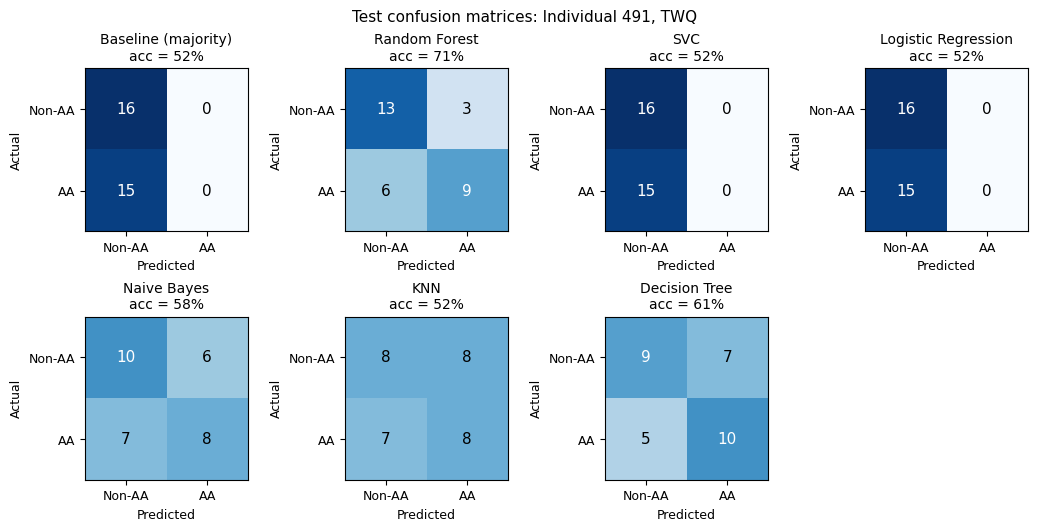

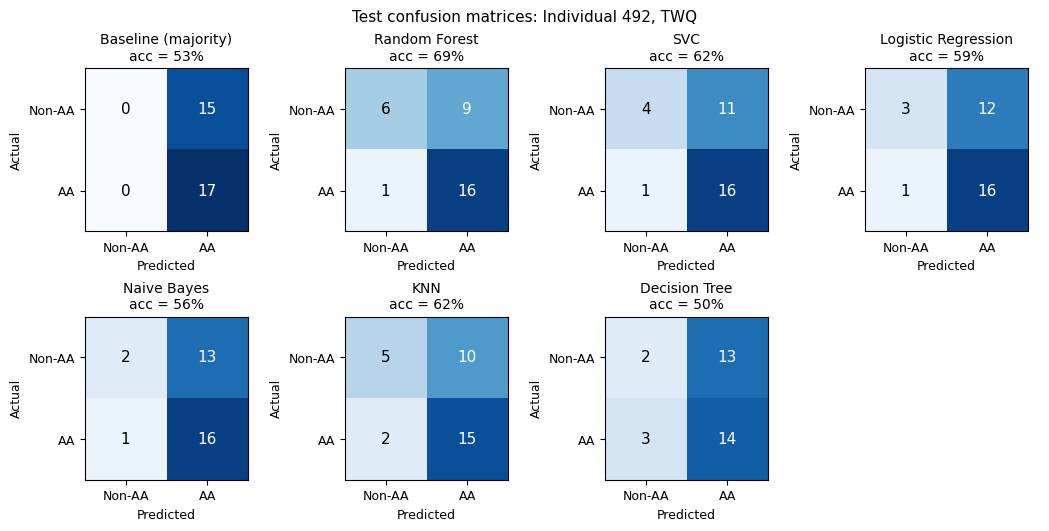

In [15]:
show_models(RESULTS, 5, ['twq'])
show_confusions(RESULTS, 5, 'twq')

## RQ2: Academic features

**Individual 491** (n_test = 31)

*Training acc* = mean accuracy over the k inner CV validation folds for the chosen hyperparameters (training split only). ★ = highest test accuracy within the feature set 

**Individual 492** (n_test = 32)

*Training acc* = mean accuracy over the k inner CV validation folds for the chosen hyperparameters (training split only). ★ = highest test accuracy within the feature set 

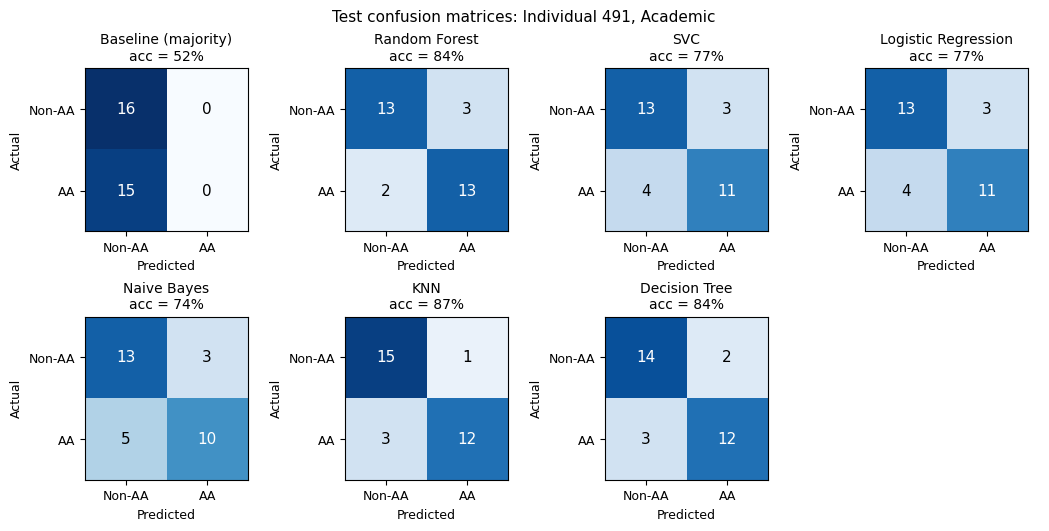

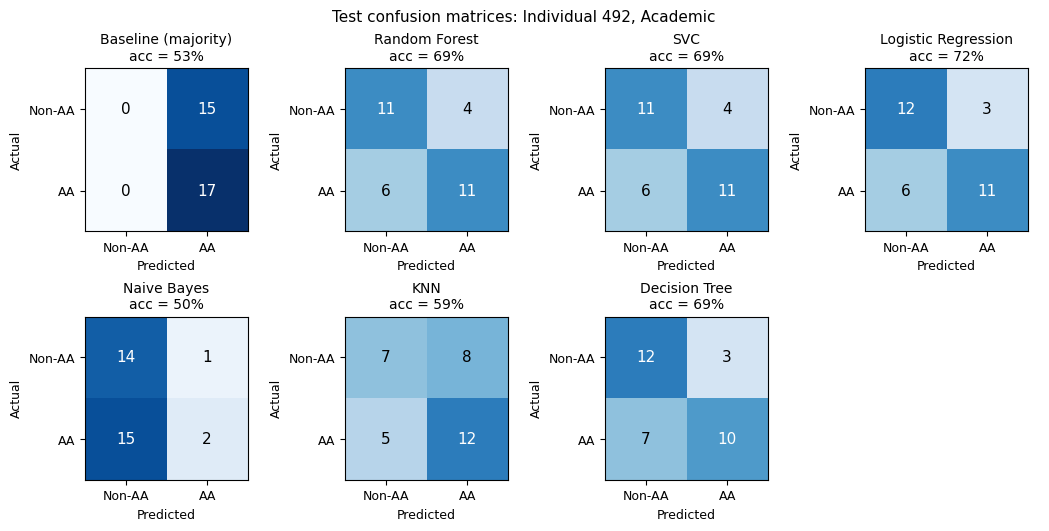

In [16]:
show_models(RESULTS, 5, ['academic'])
show_confusions(RESULTS, 5, 'academic')

## RQ3: Academic vs TWQ
The same model family is compared across the two feature sets on the same test students.

In [17]:
family_delta(RESULTS, 5, 'academic', 'twq')

**Individual 491: Academic (A) vs TWQ (B)**

,Academic test acc,TWQ test acc,Δ (A − B)
Model,,,
random_forest,84%,71%,+13% ▲
svc,77%,52%,+26% ▲
logistic_regression,77%,52%,+26% ▲
naive_bayes,74%,58%,+16% ▲
KNN,87%,52%,+35% ▲
DecisionTree,84%,61%,+23% ▲


**Individual 492: Academic (A) vs TWQ (B)**

,Academic test acc,TWQ test acc,Δ (A − B)
Model,,,
random_forest,69%,69%,+0%
svc,69%,62%,+6% ▲
logistic_regression,72%,59%,+12% ▲
naive_bayes,50%,56%,-6% ▼
KNN,59%,62%,-3% ▼
DecisionTree,69%,50%,+19% ▲


## RQ4: Combined (Academic + TWQ)

**Individual 491** (n_test = 31)

*Training acc* = mean accuracy over the k inner CV validation folds for the chosen hyperparameters (training split only). ★ = highest test accuracy within the feature set 

**Individual 492** (n_test = 32)

*Training acc* = mean accuracy over the k inner CV validation folds for the chosen hyperparameters (training split only). ★ = highest test accuracy within the feature set 

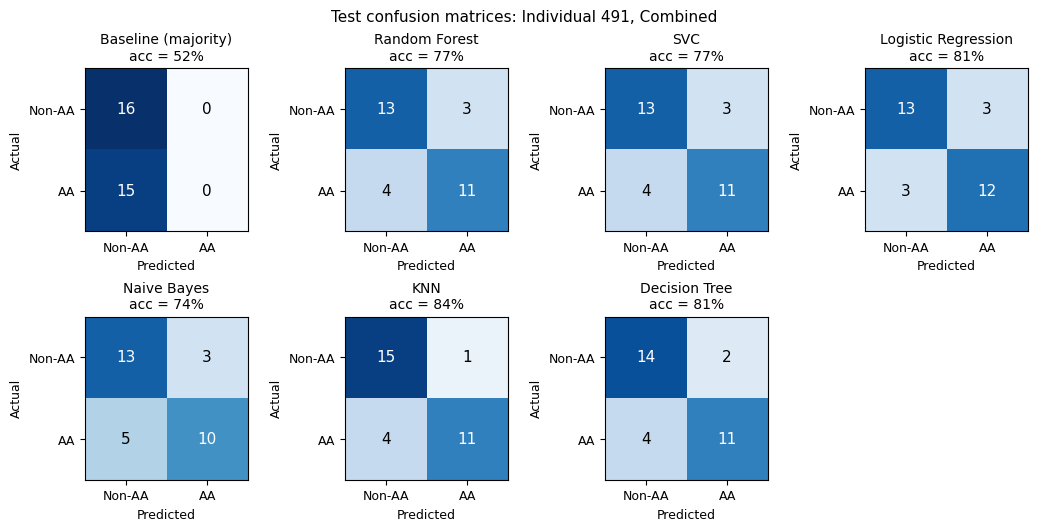

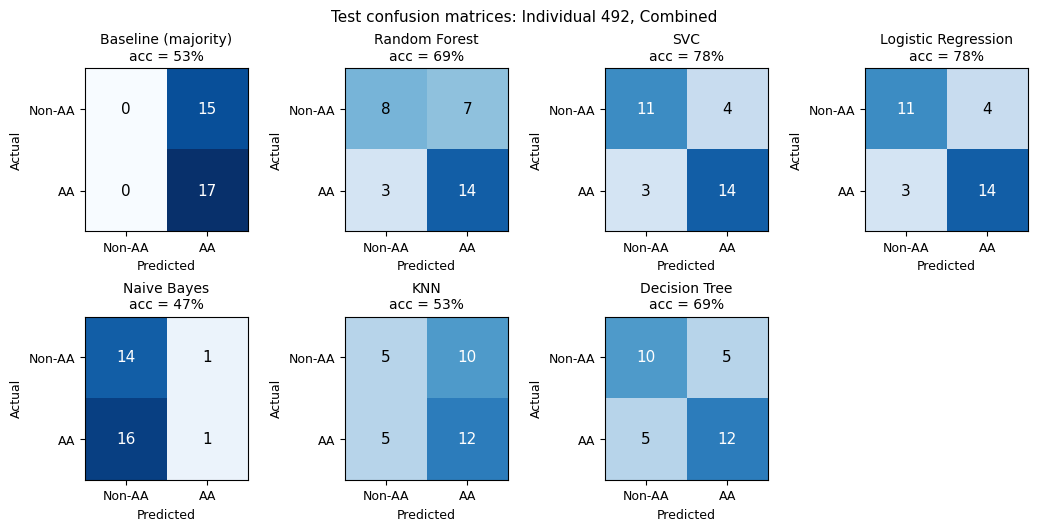

**Individual 491: Combined (A) vs TWQ (B)**

,Combined test acc,TWQ test acc,Δ (A − B)
Model,,,
random_forest,77%,71%,+6% ▲
svc,77%,52%,+26% ▲
logistic_regression,81%,52%,+29% ▲
naive_bayes,74%,58%,+16% ▲
KNN,84%,52%,+32% ▲
DecisionTree,81%,61%,+19% ▲


**Individual 492: Combined (A) vs TWQ (B)**

,Combined test acc,TWQ test acc,Δ (A − B)
Model,,,
random_forest,69%,69%,+0%
svc,78%,62%,+16% ▲
logistic_regression,78%,59%,+19% ▲
naive_bayes,47%,56%,-9% ▼
KNN,53%,62%,-9% ▼
DecisionTree,69%,50%,+19% ▲


**Individual 491: Combined (A) vs Academic (B)**

,Combined test acc,Academic test acc,Δ (A − B)
Model,,,
random_forest,77%,84%,-6% ▼
svc,77%,77%,+0%
logistic_regression,81%,77%,+3% ▲
naive_bayes,74%,74%,+0%
KNN,84%,87%,-3% ▼
DecisionTree,81%,84%,-3% ▼


**Individual 492: Combined (A) vs Academic (B)**

,Combined test acc,Academic test acc,Δ (A − B)
Model,,,
random_forest,69%,69%,+0%
svc,78%,69%,+9% ▲
logistic_regression,78%,72%,+6% ▲
naive_bayes,47%,50%,-3% ▼
KNN,53%,59%,-6% ▼
DecisionTree,69%,69%,+0%


In [18]:
show_models(RESULTS, 5, ['both'])
show_confusions(RESULTS, 5, 'both')
family_delta(RESULTS, 5, 'both', 'twq')
family_delta(RESULTS, 5, 'both', 'academic')

## RQ5: Old / New prereqs vs full Academic
The last column shows whether each family's prereq accuracy is within the 10 pp non-inferiority margin of its full-academic accuracy (descriptive; no test).

**Individual 491** (n_test = 31)

*Training acc* = mean accuracy over the k inner CV validation folds for the chosen hyperparameters (training split only). ★ = highest test accuracy within the feature set 

**Individual 492** (n_test = 32)

*Training acc* = mean accuracy over the k inner CV validation folds for the chosen hyperparameters (training split only). ★ = highest test accuracy within the feature set 

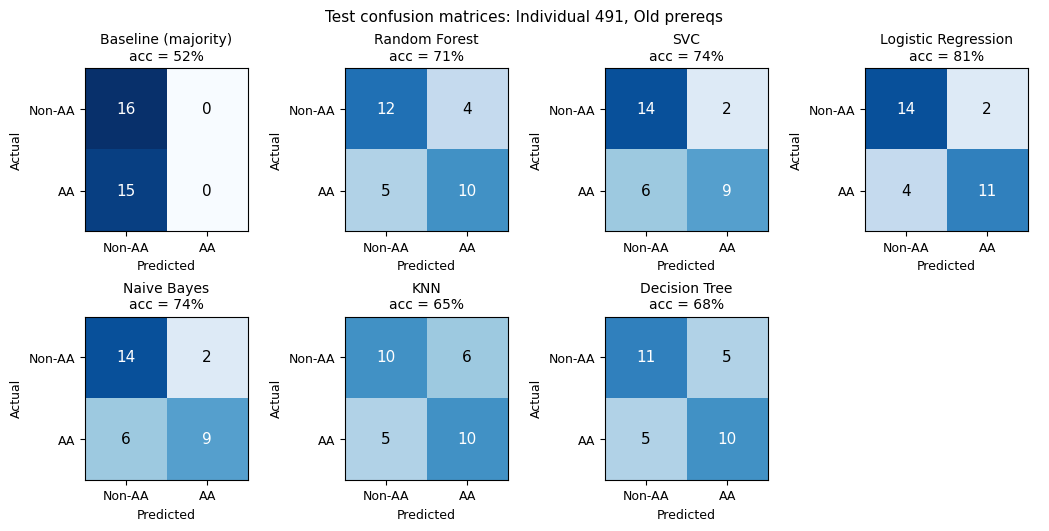

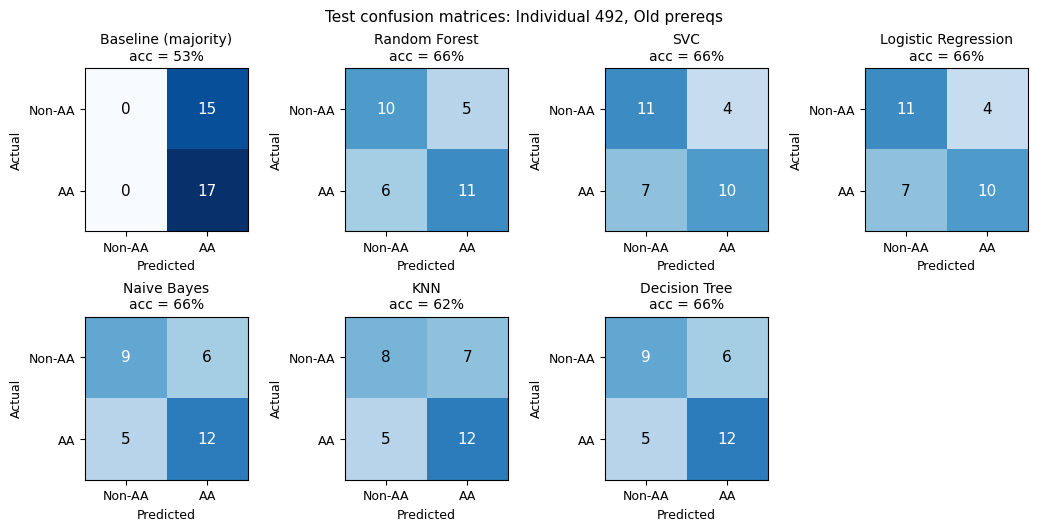

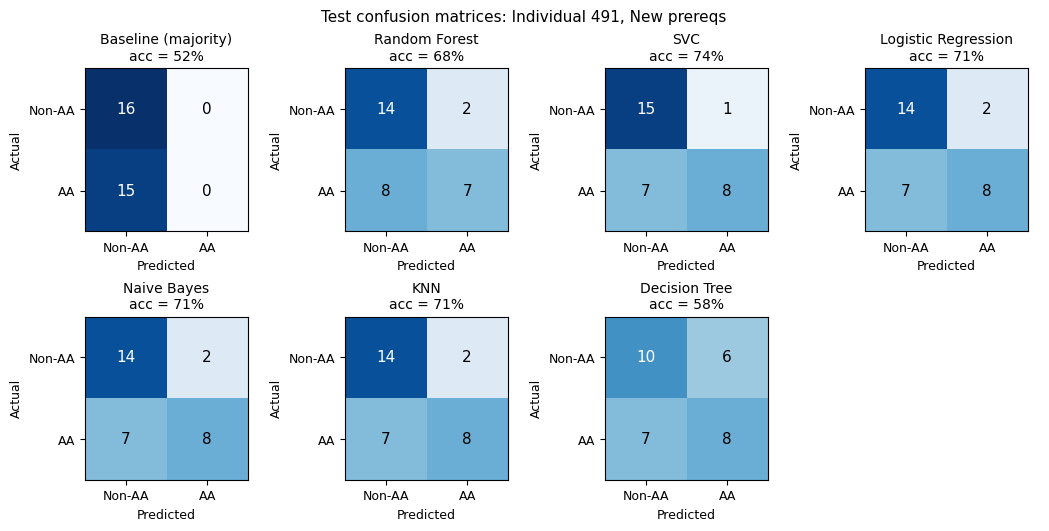

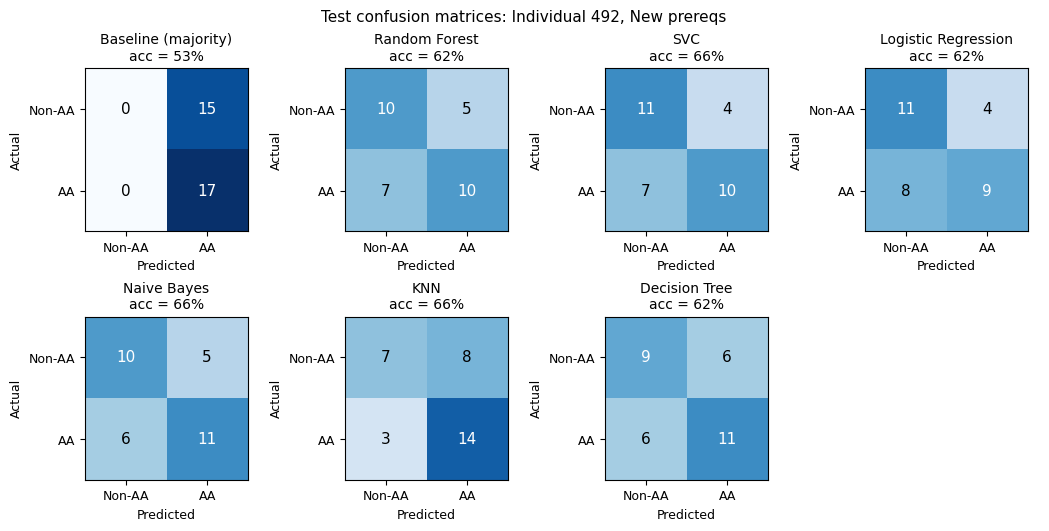

**Individual 491: Old prereqs (A) vs Academic (B)**

,Old prereqs test acc,Academic test acc,Δ (A − B),Within −10%?
Model,,,,
random_forest,71%,84%,-13% ▼,✗
svc,74%,77%,-3% ▼,✓
logistic_regression,81%,77%,+3% ▲,✓
naive_bayes,74%,74%,+0%,✓
KNN,65%,87%,-23% ▼,✗
DecisionTree,68%,84%,-16% ▼,✗


**Individual 492: Old prereqs (A) vs Academic (B)**

,Old prereqs test acc,Academic test acc,Δ (A − B),Within −10%?
Model,,,,
random_forest,66%,69%,-3% ▼,✓
svc,66%,69%,-3% ▼,✓
logistic_regression,66%,72%,-6% ▼,✓
naive_bayes,66%,50%,+16% ▲,✓
KNN,62%,59%,+3% ▲,✓
DecisionTree,66%,69%,-3% ▼,✓


**Individual 491: New prereqs (A) vs Academic (B)**

,New prereqs test acc,Academic test acc,Δ (A − B),Within −10%?
Model,,,,
random_forest,68%,84%,-16% ▼,✗
svc,74%,77%,-3% ▼,✓
logistic_regression,71%,77%,-6% ▼,✓
naive_bayes,71%,74%,-3% ▼,✓
KNN,71%,87%,-16% ▼,✗
DecisionTree,58%,84%,-26% ▼,✗


**Individual 492: New prereqs (A) vs Academic (B)**

,New prereqs test acc,Academic test acc,Δ (A − B),Within −10%?
Model,,,,
random_forest,62%,69%,-6% ▼,✓
svc,66%,69%,-3% ▼,✓
logistic_regression,62%,72%,-9% ▼,✓
naive_bayes,66%,50%,+16% ▲,✓
KNN,66%,59%,+6% ▲,✓
DecisionTree,62%,69%,-6% ▼,✓


In [19]:
show_models(RESULTS, 5, ['old-prereqs', 'new-prereqs'])
show_confusions(RESULTS, 5, 'old-prereqs')
show_confusions(RESULTS, 5, 'new-prereqs')
family_delta(RESULTS, 5, 'old-prereqs', 'academic', margin=NI_MARGIN)
family_delta(RESULTS, 5, 'new-prereqs', 'academic', margin=NI_MARGIN)

# Appendix: Cross-batch (batch1 → batch2)
A separate test: models are tuned with team-disjoint k-fold CV on **all of batch1** and evaluated once on **all of batch2**. The baseline is batch1's majority class. For 491 that majority does not match batch2's, so the baseline is weak there.

## Cross-batch (k = 5)

In [20]:
show_models(XBATCH, 5, list(FEATURE_FNS))

**Individual 491** (n_test = 50)

*Training acc* = mean accuracy over the k inner CV validation folds for the chosen hyperparameters (training split only). ★ = highest test accuracy within the feature set 

**Individual 492** (n_test = 50)

*Training acc* = mean accuracy over the k inner CV validation folds for the chosen hyperparameters (training split only). ★ = highest test accuracy within the feature set 